# Kompleksowa Analiza Statystyczna - Zbiór Danych Detekcji Phishingu

Ten notebook zawiera szczegółową analizę statystyczną zbioru danych detekcji phishingu obejmującą:

1. Import bibliotek i wczytanie danych
2. Przetwarzanie wstępne i czyszczenie danych
3. Statystyki opisowe
4. Analiza korelacji
5. Analiza ważności cech
6. Analiza rozkładów i testy normalności
7. Wizualizacja - Mapa ciepła korelacji
8. Wizualizacja - Wykres słupkowy ważności cech
9. Wizualizacja - Porównanie rozkładów według klas
10. Zaawansowana analiza selekcji cech
11. Tworzenie zoptymalizowanego zbioru danych do ML


## 1. Import Bibliotek i Wczytanie Danych


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import warnings
import os

warnings.filterwarnings('ignore')

output_dir = '../static/statistical_analysis'
os.makedirs(output_dir, exist_ok=True)

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10

df = pd.read_csv('../data/dataset_full.csv')
print("✅ Dane załadowane pomyślnie!")
print(f"Rozmiar zbioru danych: {df.shape}")
print(f"\nPierwszych 5 wierszy:")
df.head()

✅ Dane załadowane pomyślnie!
Rozmiar zbioru danych: (88647, 112)

Pierwszych 5 wierszy:


,qty_dot_url,qty_hyphen_url,qty_underline_url,qty_slash_url,qty_questionmark_url,qty_equal_url,qty_at_url,qty_and_url,qty_exclamation_url,qty_space_url,...,qty_ip_resolved,qty_nameservers,qty_mx_servers,ttl_hostname,tls_ssl_certificate,qty_redirects,url_google_index,domain_google_index,url_shortened,phishing
0,3,0,0,1,0,0,0,0,0,0,...,1,2,0,892,0,0,0,0,0,1
1,5,0,1,3,0,3,0,2,0,0,...,1,2,1,9540,1,0,0,0,0,1
2,2,0,0,1,0,0,0,0,0,0,...,1,2,3,589,1,0,0,0,0,0
3,4,0,2,5,0,0,0,0,0,0,...,1,2,0,292,1,0,0,0,0,1
4,2,0,0,0,0,0,0,0,0,0,...,1,2,1,3597,0,1,0,0,0,0


## 2. Przetwarzanie Wstępne - Czyszczenie i Obsługa Brakujących Danych


In [2]:
def clean_and_analyze_data(df):
    print("=" * 80)
    print("ANALIZA JAKOŚCI DANYCH")
    print("=" * 80)

    print("\n1. PRZEGLĄD ZBIORU DANYCH:")
    print(f"   • Wiersze: {df.shape[0]:,}")
    print(f"   • Kolumny: {df.shape[1]}")
    print(f"   • Cechy: {df.shape[1] - 1}")
    print(f"   • Zmienna docelowa: {df.columns[-1]}")

    print("\n2. TYPY DANYCH:")
    dtype_counts = df.dtypes.value_counts()
    for dtype, count in dtype_counts.items():
        print(f"   • {dtype}: {count} kolumn")

    print("\n3. ANALIZA BRAKUJĄCYCH WARTOŚCI:")
    missing_values = df.isnull().sum()
    missing_percentage = (missing_values / len(df)) * 100
    missing_df = pd.DataFrame({
        'Kolumna': missing_values.index,
        'Brakujące': missing_values.values,
        'Procent': missing_percentage.values
    })

    if missing_values.sum() == 0:
        print("   ✅ Nie znaleziono brakujących wartości!")
    else:
        print("   ⚠️  Wykryto brakujące wartości:")
        print(missing_df[missing_df['Brakujące'] > 0])

    print("\n4. ANALIZA DUPLIKATÓW:")
    duplicates = df.duplicated().sum()
    print(f"   • Zduplikowane wiersze: {duplicates} ({duplicates/len(df)*100:.2f}%)")

    print("\n5. ROZKŁAD ZMIENNEJ DOCELOWEJ:")
    target_col = df.columns[-1]
    target_counts = df[target_col].value_counts().sort_index()

    for value, count in target_counts.items():
        percentage = (count / len(df)) * 100
        label = "Bez phishingu" if value == 0 else "Phishing"
        print(f"   • {label} (klasa {value}): {count:,} próbek ({percentage:.1f}%)")

    class_ratio = target_counts.min() / target_counts.max()
    print(f"\n   Współczynnik balansu klas: {class_ratio:.2f}")
    if class_ratio < 0.5:
        print("   ⚠️  Zbiór jest niezbalansowany - rozważ użycie class_weight='balanced'")
    else:
        print("   ✅ Zbiór jest rozsądnie zbalansowany")

    print("\n6. ANALIZA WARTOŚCI ODSTAJĄCYCH (metoda IQR):")
    numeric_cols = df.select_dtypes(include=[np.number]).columns[:-1]

    total_outliers = 0
    cols_with_outliers = 0

    for column in numeric_cols:
        Q1 = df[column].quantile(0.25)
        Q3 = df[column].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

        if len(outliers) > 0:
            total_outliers += len(outliers)
            cols_with_outliers += 1

    print(f"   • Kolumny z wartościami odstającymi: {cols_with_outliers}/{len(numeric_cols)}")
    print(f"   • Łączna liczba wartości odstających: {total_outliers:,}")
    print(f"   • Procent wartości odstających: {total_outliers/(len(df)*len(numeric_cols))*100:.2f}%)")

    df_clean = df.copy()

    if duplicates > 0:
        df_clean = df_clean.drop_duplicates()
        print(f"\n7. AKCJE CZYSZCZENIA:")
        print(f"   ✓ Usunięto {duplicates} zduplikowanych wierszy")

    print("\n" + "=" * 80)
    print("CZYSZCZENIE DANYCH ZAKOŃCZONE")
    print("=" * 80)
    print(f"Końcowy rozmiar zbioru danych: {df_clean.shape}")

    return df_clean

df_clean = clean_and_analyze_data(df)

ANALIZA JAKOŚCI DANYCH

1. PRZEGLĄD ZBIORU DANYCH:
   • Wiersze: 88,647
   • Kolumny: 112
   • Cechy: 111
   • Zmienna docelowa: phishing

2. TYPY DANYCH:
   • int64: 111 kolumn
   • float64: 1 kolumn

3. ANALIZA BRAKUJĄCYCH WARTOŚCI:
   ✅ Nie znaleziono brakujących wartości!

4. ANALIZA DUPLIKATÓW:
   • Zduplikowane wiersze: 1438 (1.62%)

5. ROZKŁAD ZMIENNEJ DOCELOWEJ:
   • Bez phishingu (klasa 0): 58,000 próbek (65.4%)
   • Phishing (klasa 1): 30,647 próbek (34.6%)

   Współczynnik balansu klas: 0.53
   ✅ Zbiór jest rozsądnie zbalansowany

6. ANALIZA WARTOŚCI ODSTAJĄCYCH (metoda IQR):
   • Kolumny z wartościami odstającymi: 91/111
   • Łączna liczba wartości odstających: 380,315
   • Procent wartości odstających: 3.87%)

7. AKCJE CZYSZCZENIA:
   ✓ Usunięto 1438 zduplikowanych wierszy

CZYSZCZENIE DANYCH ZAKOŃCZONE
Końcowy rozmiar zbioru danych: (87209, 112)
   • Kolumny z wartościami odstającymi: 91/111
   • Łączna liczba wartości odstających: 380,315
   • Procent wartości odstającyc

## 3. Statystyki Opisowe


In [3]:
def calculate_descriptive_statistics(df):
    print("=" * 80)
    print("ANALIZA STATYSTYK OPISOWYCH")
    print("=" * 80)

    numeric_columns = df.select_dtypes(include=[np.number]).columns[:-1]

    stats_dict = {}

    for column in numeric_columns:
        data = df[column]

        stats_dict[column] = {
            'Min': data.min(),
            'Max': data.max(),
            'Zakres': data.max() - data.min(),
            'Średnia': data.mean(),
            'Odch.std': data.std(),
            'Mediana': data.median(),
            'Q1': data.quantile(0.25),
            'Q3': data.quantile(0.75),
            'IQR': data.quantile(0.75) - data.quantile(0.25),
            'Skośność': data.skew(),
            'Kurtoza': data.kurtosis()
        }

    stats_df = pd.DataFrame(stats_dict).T

    print("\nPODSTAWOWE STATYSTYKI (Top 20 cech):")
    print("=" * 80)
    print(stats_df[['Min', 'Max', 'Średnia', 'Odch.std', 'Mediana']].head(20).round(3))

    print("\nKSZTAŁT ROZKŁADU (Top 20 cech):")
    print("=" * 80)
    print(stats_df[['Skośność', 'Kurtoza']].head(20).round(3))

    stats_df.round(4).to_csv(f'{output_dir}/descriptive_statistics.csv')
    print(f"\n✓ Statystyki zapisane do: {output_dir}/descriptive_statistics.csv")

    print("\nINTERPRETACJA ROZKŁADU:")
    print("=" * 80)

    highly_skewed = stats_df[abs(stats_df['Skośność']) > 1].index.tolist()
    highly_kurtotic = stats_df[abs(stats_df['Kurtoza']) > 3].index.tolist()

    print(f"   • Silnie skośne cechy (|skośność| > 1): {len(highly_skewed)}")
    if len(highly_skewed) > 0:
        print(f"     Przykłady: {', '.join(highly_skewed[:5])}")

    print(f"   • Silnie kurtyczne cechy (|kurtoza| > 3): {len(highly_kurtotic)}")
    if len(highly_kurtotic) > 0:
        print(f"     Przykłady: {', '.join(highly_kurtotic[:5])}")

    return stats_df

descriptive_stats = calculate_descriptive_statistics(df_clean)

ANALIZA STATYSTYK OPISOWYCH

PODSTAWOWE STATYSTYKI (Top 20 cech):
                      Min     Max  Średnia  Odch.std  Mediana
qty_dot_url           1.0    24.0    2.194     1.239      2.0
qty_hyphen_url        0.0    35.0    0.332     1.126      0.0
qty_underline_url     0.0    21.0    0.115     0.662      0.0
qty_slash_url         0.0    44.0    1.293     1.896      0.0
qty_questionmark_url  0.0     9.0    0.009     0.112      0.0
qty_equal_url         0.0    23.0    0.207     0.959      0.0
qty_at_url            0.0    43.0    0.022     0.282      0.0
qty_and_url           0.0    26.0    0.142     0.930      0.0
qty_exclamation_url   0.0    10.0    0.003     0.088      0.0
qty_space_url         0.0     9.0    0.001     0.073      0.0
qty_tilde_url         0.0     5.0    0.003     0.079      0.0
qty_comma_url         0.0    11.0    0.002     0.070      0.0
qty_plus_url          0.0    19.0    0.003     0.112      0.0
qty_asterisk_url      0.0    60.0    0.005     0.304      0.0
qty_

## 4. Analiza Korelacji


In [4]:
def analyze_correlations(df):
    print("=" * 80)
    print("ANALIZA KORELACJI")
    print("=" * 80)

    numeric_columns = df.select_dtypes(include=[np.number]).columns
    target_col = df.columns[-1]
    feature_cols = [col for col in numeric_columns if col != target_col]

    print("\n1. KORELACJE ZE ZMIENNĄ DOCELOWĄ (phishing):")
    print("=" * 80)

    target_correlations = []
    for column in feature_cols:
        corr_coef, p_value = pearsonr(df[column], df[target_col])
        target_correlations.append({
            'Cecha': column,
            'Korelacja': corr_coef,
            'Abs_Korelacja': abs(corr_coef),
            'wartość-p': p_value,
            'Znacząca': 'Tak' if p_value < 0.05 else 'Nie'
        })

    target_corr_df = pd.DataFrame(target_correlations)
    target_corr_df = target_corr_df.sort_values('Abs_Korelacja', ascending=False)

    print("\nTop 20 Cech Najbardziej Skorelowanych z Phishingiem:")
    print(target_corr_df.head(20)[['Cecha', 'Korelacja', 'wartość-p', 'Znacząca']].to_string(index=False))

    print("\n2. ROZKŁAD SIŁY KORELACJI:")
    print("=" * 80)

    very_strong = len(target_corr_df[target_corr_df['Abs_Korelacja'] >= 0.8])
    strong = len(target_corr_df[(target_corr_df['Abs_Korelacja'] >= 0.6) & (target_corr_df['Abs_Korelacja'] < 0.8)])
    moderate = len(target_corr_df[(target_corr_df['Abs_Korelacja'] >= 0.4) & (target_corr_df['Abs_Korelacja'] < 0.6)])
    weak = len(target_corr_df[(target_corr_df['Abs_Korelacja'] >= 0.2) & (target_corr_df['Abs_Korelacja'] < 0.4)])
    very_weak = len(target_corr_df[target_corr_df['Abs_Korelacja'] < 0.2])

    print(f"   • Bardzo Silne (|r| ≥ 0.8): {very_strong} cech")
    print(f"   • Silne (0.6 ≤ |r| < 0.8): {strong} cech")
    print(f"   • Umiarkowane (0.4 ≤ |r| < 0.6): {moderate} cech")
    print(f"   • Słabe (0.2 ≤ |r| < 0.4): {weak} cech")
    print(f"   • Bardzo Słabe (|r| < 0.2): {very_weak} cech")

    print("\n3. ANALIZA WIELOKOLINEARNOŚCI:")
    print("=" * 80)

    correlation_matrix = df[numeric_columns].corr()

    high_corr_pairs = []
    for i in range(len(feature_cols)):
        for j in range(i+1, len(feature_cols)):
            corr = correlation_matrix.iloc[i, j]
            if abs(corr) > 0.7:
                high_corr_pairs.append({
                    'Cecha 1': feature_cols[i],
                    'Cecha 2': feature_cols[j],
                    'Korelacja': corr
                })

    if high_corr_pairs:
        high_corr_df = pd.DataFrame(high_corr_pairs)
        high_corr_df = high_corr_df.sort_values('Korelacja', key=abs, ascending=False)
        print(f"   Znaleziono {len(high_corr_pairs)} wysoko skorelowanych par cech (|r| > 0.7)")
        print("\n   Top 10 skorelowanych par:")
        print(high_corr_df.head(10).to_string(index=False))
    else:
        print("   ✅ Nie wykryto wysokiej wielokolinearności (|r| > 0.7)")

    target_corr_df.to_csv(f'{output_dir}/target_correlations.csv', index=False)
    print(f"\n✓ Analiza korelacji zapisana do: {output_dir}/target_correlations.csv")

    return target_corr_df, correlation_matrix

target_correlations, correlation_matrix = analyze_correlations(df_clean)

ANALIZA KORELACJI

1. KORELACJE ZE ZMIENNĄ DOCELOWĄ (phishing):

Top 20 Cech Najbardziej Skorelowanych z Phishingiem:
                     Cecha  Korelacja  wartość-p Znacząca
       qty_slash_directory   0.744679        0.0      Tak
            qty_slash_file   0.744558        0.0      Tak
qty_questionmark_directory   0.744558        0.0      Tak
     qty_hashtag_directory   0.744558        0.0      Tak
     qty_questionmark_file   0.744558        0.0      Tak
           qty_dollar_file   0.744558        0.0      Tak
          qty_hashtag_file   0.744558        0.0      Tak
               qty_at_file   0.744421        0.0      Tak
      qty_exclamation_file   0.743961        0.0      Tak
              qty_and_file   0.743759        0.0      Tak
            qty_tilde_file   0.743558        0.0      Tak
            qty_equal_file   0.742574        0.0      Tak
            qty_comma_file   0.742260        0.0      Tak
       qty_comma_directory   0.742144        0.0      Tak
            

## 5. Analiza Ważności Cech (Random Forest)


In [5]:
def analyze_feature_importance(df):
    print("=" * 80)
    print("ANALIZA WAŻNOŚCI CECH (Random Forest)")
    print("=" * 80)

    X = df.iloc[:, :-1]
    y = df.iloc[:, -1]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    print(f"Uczenie modelu Random Forest na {len(X_train):,} próbkach...")

    rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, max_depth=10)
    rf.fit(X_train, y_train)

    feature_importance = pd.DataFrame({
        'Cecha': X.columns,
        'Ważność': rf.feature_importances_
    }).sort_values('Ważność', ascending=False)

    train_score = rf.score(X_train, y_train)
    test_score = rf.score(X_test, y_test)

    print(f"\nWydajność Modelu:")
    print(f"   • Dokładność uczenia: {train_score:.4f}")
    print(f"   • Dokładność testowania: {test_score:.4f}")

    print("\nTop 20 Najważniejszych Cech:")
    print("=" * 80)
    for i, row in feature_importance.head(20).iterrows():
        print(f"   {i+1:2d}. {row['Cecha']:30s}: {row['Ważność']:.6f} ({row['Ważność']*100:.2f}%)")

    print("\nBottom 20 Najmniej Ważnych Cech:")
    print("=" * 80)
    for i, row in feature_importance.tail(20).iterrows():
        print(f"   {row['Cecha']:30s}: {row['Ważność']:.6f} ({row['Ważność']*100:.2f}%)")

    print("\nREKOMENDACJE SELEKCJI CECH:")
    print("=" * 80)

    important_features = feature_importance[feature_importance['Ważność'] > 0.01]
    print(f"   • Cechy z >1% ważnością: {len(important_features)}")

    low_importance = feature_importance[feature_importance['Ważność'] < 0.001]
    print(f"   • Cechy z <0.1% ważnością: {len(low_importance)} (rozważ usunięcie)")

    feature_importance.to_csv(f'{output_dir}/feature_importance_rf.csv', index=False)
    print(f"\n✓ Ważność cech zapisana do: {output_dir}/feature_importance_rf.csv")

    return feature_importance

feature_importance = analyze_feature_importance(df_clean)


ANALIZA WAŻNOŚCI CECH (Random Forest)
Uczenie modelu Random Forest na 69,767 próbkach...

Wydajność Modelu:
   • Dokładność uczenia: 0.9558
   • Dokładność testowania: 0.9505

Top 20 Najważniejszych Cech:
   58. directory_length              : 0.142658 (14.27%)
   56. qty_dollar_directory          : 0.056720 (5.67%)
   59. qty_dot_file                  : 0.052860 (5.29%)
   101. time_domain_activation        : 0.051460 (5.15%)
   44. qty_slash_directory           : 0.041214 (4.12%)
   19. length_url                    : 0.031596 (3.16%)
    4. qty_slash_url                 : 0.031100 (3.11%)
   43. qty_underline_directory       : 0.029093 (2.91%)
   52. qty_comma_directory           : 0.028295 (2.83%)
   57. qty_percent_directory         : 0.028109 (2.81%)
   65. qty_at_file                   : 0.028078 (2.81%)
   48. qty_and_directory             : 0.027947 (2.79%)
   76. file_length                   : 0.022855 (2.29%)
   41. qty_dot_directory             : 0.022305 (2.23%)
   63. qt

## 6. Analiza Rozkładów i Testy Normalności


In [6]:
def analyze_distributions(df, sample_size=1000):
    print("=" * 80)
    print("ANALIZA ROZKŁADÓW")
    print("=" * 80)

    numeric_columns = df.select_dtypes(include=[np.number]).columns[:-1]

    normality_results = []

    for column in numeric_columns:
        if len(df) > sample_size:
            sample_data = df[column].sample(sample_size, random_state=42)
        else:
            sample_data = df[column]

        try:
            statistic, p_value = stats.shapiro(sample_data)
            is_normal = p_value > 0.05
        except:
            statistic, p_value = 0, 0
            is_normal = False

        normality_results.append({
            'Cecha': column,
            'Statystyka Shapiro-Wilk': statistic,
            'wartość-p': p_value,
            'Rozkład Normalny': 'Tak' if is_normal else 'Nie',
            'Skośność': df[column].skew(),
            'Kurtoza': df[column].kurtosis()
        })

    normality_df = pd.DataFrame(normality_results)

    normal_count = len(normality_df[normality_df['Rozkład Normalny'] == 'Tak'])
    non_normal_count = len(normality_df) - normal_count

    print(f"\nWyniki Testu Normalności (Shapiro-Wilk, α=0.05):")
    print(f"   • Cechy z rozkładem normalnym: {normal_count} ({normal_count/len(normality_df)*100:.1f}%)")
    print(f"   • Cechy z rozkładem nienormalnym: {non_normal_count} ({non_normal_count/len(normality_df)*100:.1f}%)")

    print("\nTop 10 Najbardziej Normalnych Cech:")
    print(normality_df.sort_values('wartość-p', ascending=False).head(10)[['Cecha', 'wartość-p', 'Rozkład Normalny']].to_string(index=False))

    print("\nTop 10 Najbardziej Skośnych Cech:")
    print(normality_df.sort_values('Skośność', key=abs, ascending=False).head(10)[['Cecha', 'Skośność', 'Kurtoza']].to_string(index=False))

    normality_df.to_csv(f'{output_dir}/distribution_analysis.csv', index=False)
    print(f"\n✓ Analiza rozkładu zapisana do: {output_dir}/distribution_analysis.csv")

    return normality_df

distribution_analysis = analyze_distributions(df_clean)

ANALIZA ROZKŁADÓW

Wyniki Testu Normalności (Shapiro-Wilk, α=0.05):
   • Cechy z rozkładem normalnym: 17 (15.3%)
   • Cechy z rozkładem nienormalnym: 94 (84.7%)

Top 10 Najbardziej Normalnych Cech:
                 Cecha  wartość-p Rozkład Normalny
       qty_plus_domain        1.0              Tak
  qty_underline_domain        1.0              Tak
    qty_percent_domain        1.0              Tak
     qty_dollar_domain        1.0              Tak
    qty_hashtag_domain        1.0              Tak
   qty_asterisk_domain        1.0              Tak
      qty_comma_domain        1.0              Tak
      qty_tilde_domain        1.0              Tak
      qty_space_domain        1.0              Tak
qty_exclamation_domain        1.0              Tak

Top 10 Najbardziej Skośnych Cech:
              Cecha   Skośność      Kurtoza
      qty_at_domain 295.311700 87209.000000
    qty_hashtag_url 160.813283 29024.501138
   qty_asterisk_url 119.331974 19310.444692
      qty_space_url  97.469061

## 7. Wizualizacja - Mapa Ciepła Korelacji



Tworzenie mapy ciepła korelacji...


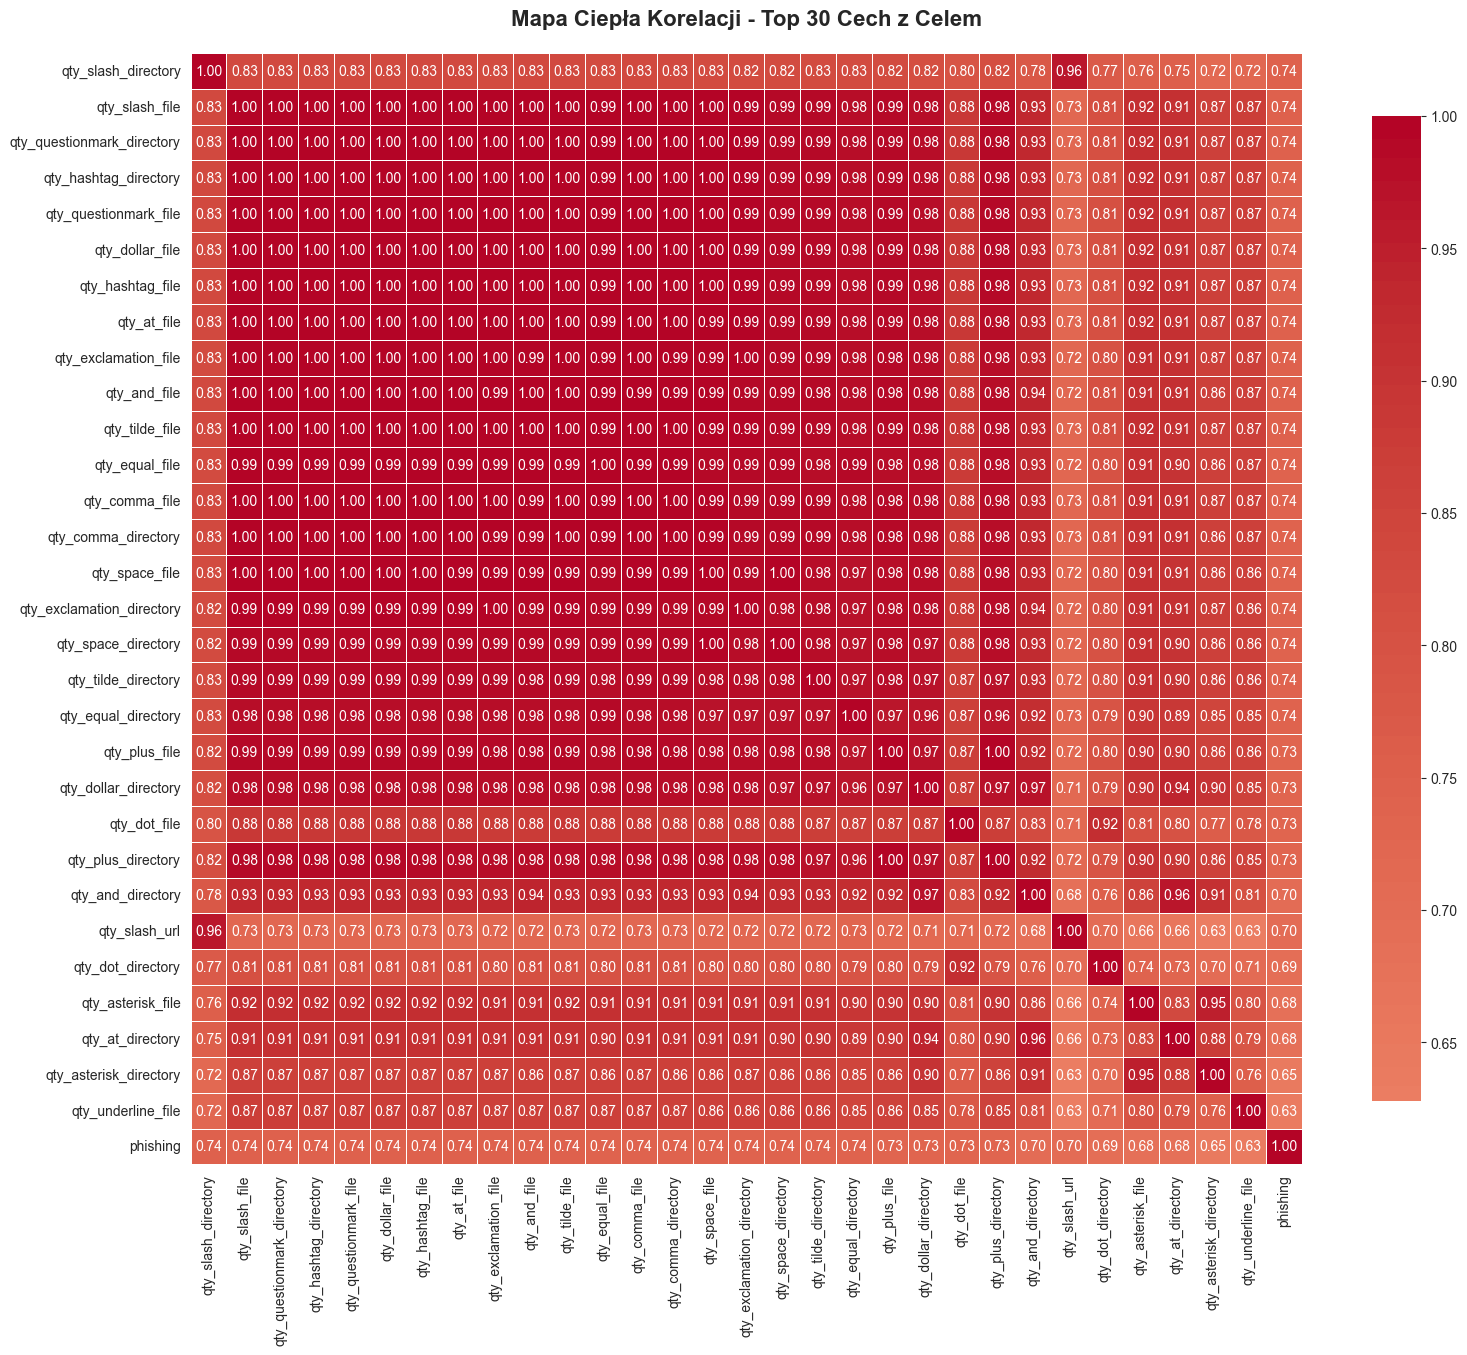

✓ Mapa ciepła zapisana do: ../static/statistical_analysis/correlation_heatmap.png


In [7]:
def create_correlation_heatmap(df, top_n=30):
    print("\nTworzenie mapy ciepła korelacji...")

    target_col = df.columns[-1]
    feature_cols = df.select_dtypes(include=[np.number]).columns[:-1]

    correlations_with_target = df[feature_cols].corrwith(df[target_col]).abs().sort_values(ascending=False)
    top_features = correlations_with_target.head(top_n).index.tolist()
    top_features.append(target_col)

    corr_matrix = df[top_features].corr()

    plt.figure(figsize=(16, 14))
    sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
                square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
    plt.title(f'Mapa Ciepła Korelacji - Top {top_n} Cech z Celem',
              fontsize=16, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.savefig(f'{output_dir}/correlation_heatmap.png', dpi=300, bbox_inches='tight')
    plt.show()

    print(f"✓ Mapa ciepła zapisana do: {output_dir}/correlation_heatmap.png")

    return corr_matrix

correlation_heatmap = create_correlation_heatmap(df_clean, top_n=30)

## 8. Wizualizacja - Wykres Słupkowy Ważności Cech



Tworzenie wykresu ważności cech...


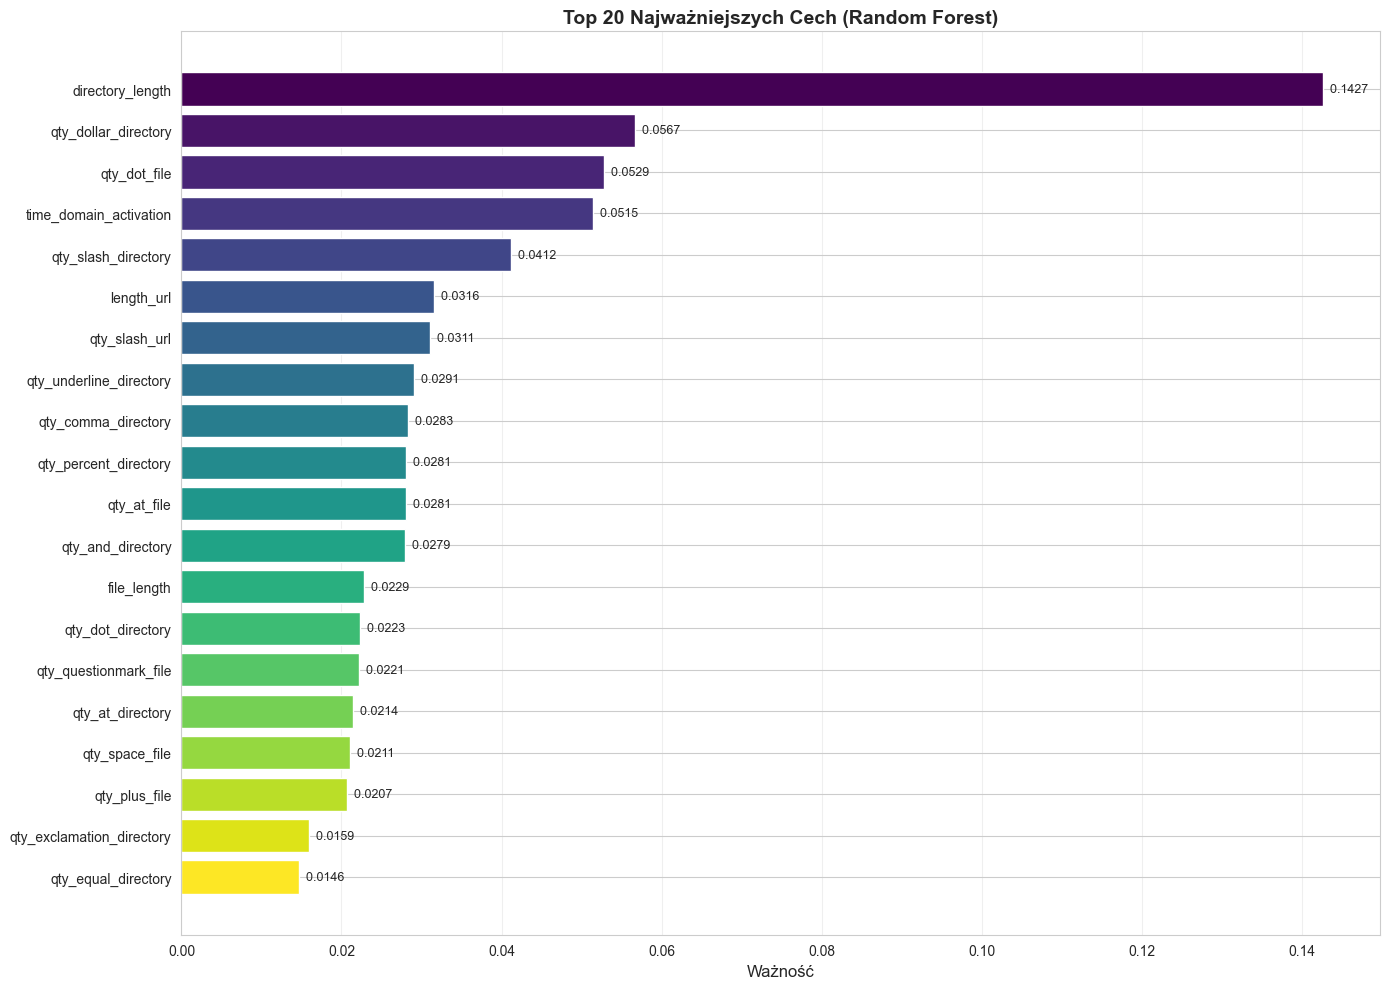

✓ Wykres ważności cech zapisany do: ../static/statistical_analysis/feature_importance.png


In [8]:
def plot_feature_importance(feature_importance_df, top_n=20):
    print("\nTworzenie wykresu ważności cech...")

    top_features = feature_importance_df.head(top_n)

    plt.figure(figsize=(14, 10))
    colors = plt.cm.viridis(np.linspace(0, 1, len(top_features)))

    bars = plt.barh(range(len(top_features)), top_features['Ważność'], color=colors)
    plt.yticks(range(len(top_features)), top_features['Cecha'])
    plt.xlabel('Ważność', fontsize=12)
    plt.title(f'Top {top_n} Najważniejszych Cech (Random Forest)',
              fontsize=14, fontweight='bold')
    plt.gca().invert_yaxis()
    plt.grid(axis='x', alpha=0.3)

    for i, (bar, val) in enumerate(zip(bars, top_features['Ważność'])):
        plt.text(val, i, f'  {val:.4f}', va='center', fontsize=9)

    plt.tight_layout()
    plt.savefig(f'{output_dir}/feature_importance.png', dpi=300, bbox_inches='tight')
    plt.show()

    print(f"✓ Wykres ważności cech zapisany do: {output_dir}/feature_importance.png")

plot_feature_importance(feature_importance, top_n=20)

## 9. Wizualizacja - Porównanie Rozkładów według Klas



Tworzenie wykresów porównania rozkładów...


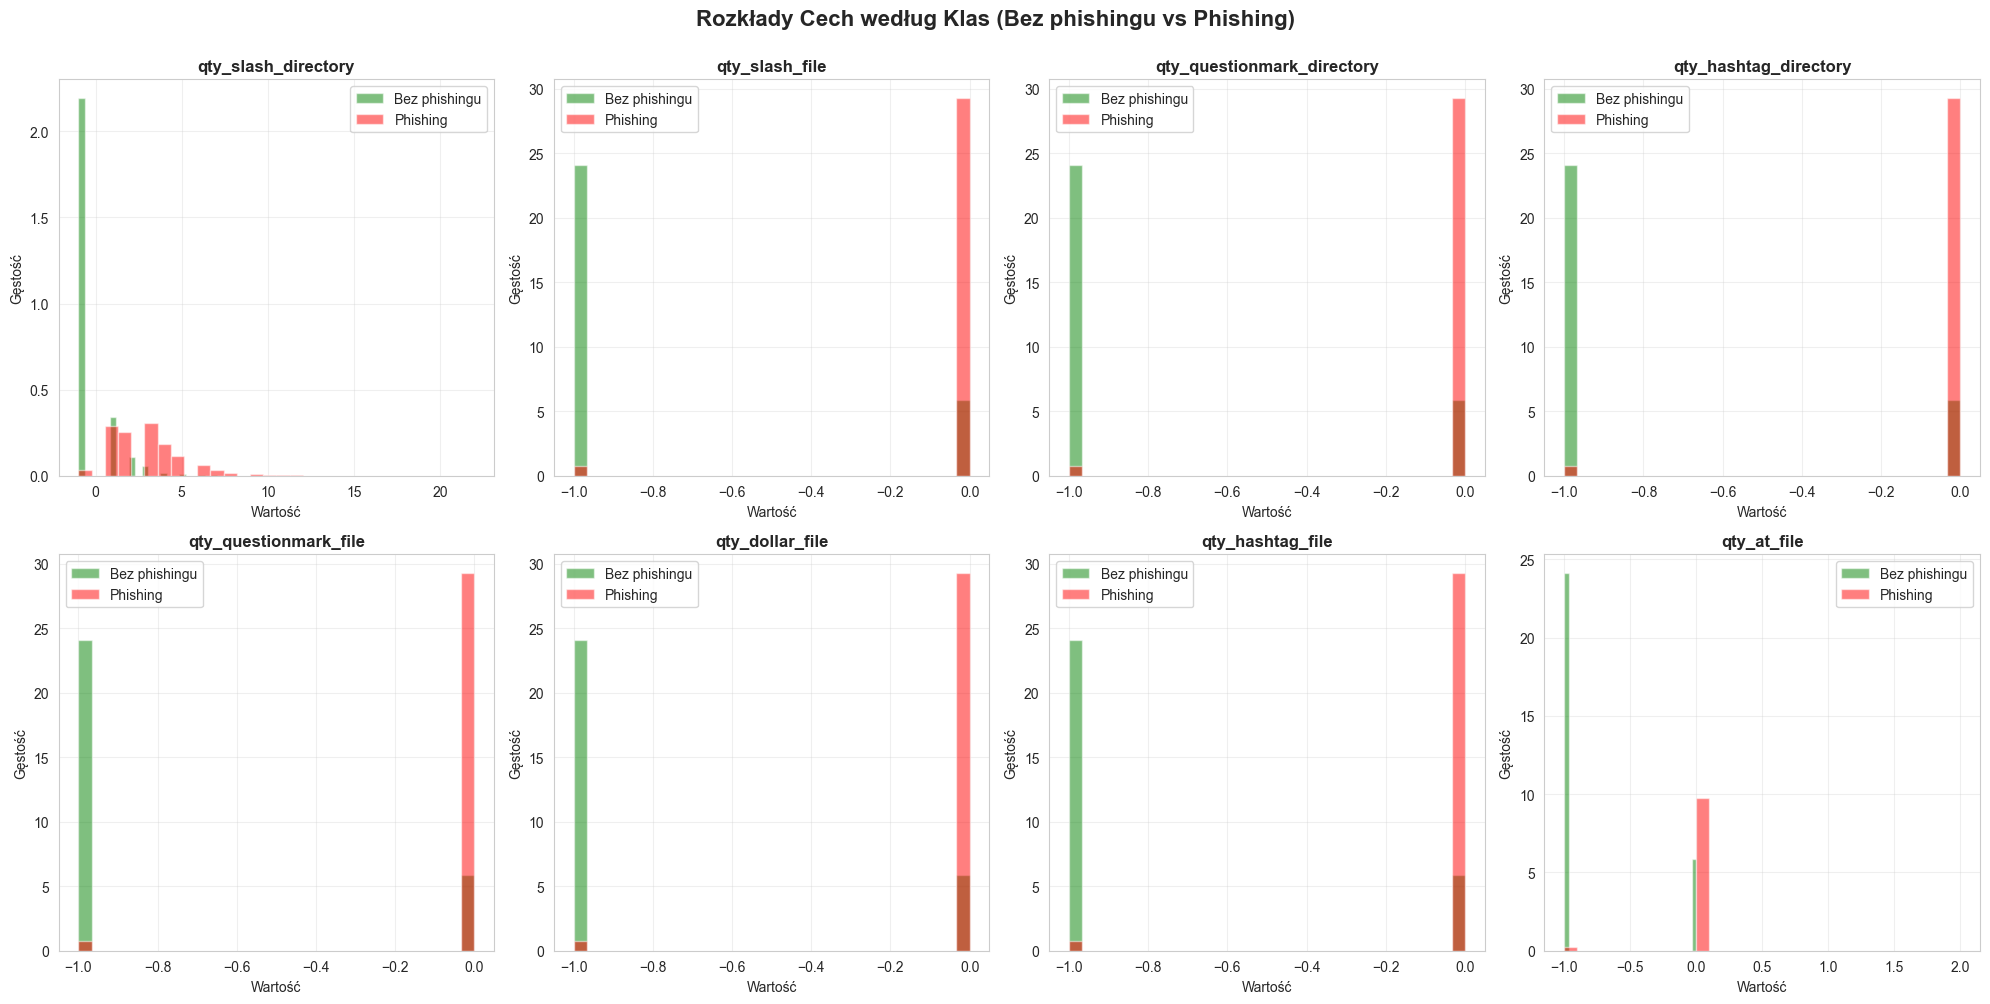

✓ Porównanie rozkładów zapisane do: ../static/statistical_analysis/distribution_by_class.png


In [9]:
def plot_distribution_by_class(df, top_n=8):
    print("\nTworzenie wykresów porównania rozkładów...")

    target_col = df.columns[-1]
    feature_cols = df.select_dtypes(include=[np.number]).columns[:-1]

    correlations = df[feature_cols].corrwith(df[target_col]).abs().sort_values(ascending=False)
    top_features = correlations.head(top_n).index.tolist()

    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    axes = axes.flatten()

    for i, feature in enumerate(top_features):
        legitimate = df[df[target_col] == 0][feature]
        phishing = df[df[target_col] == 1][feature]

        axes[i].hist(legitimate, bins=30, alpha=0.5, label='Bez phishingu', color='green', density=True)
        axes[i].hist(phishing, bins=30, alpha=0.5, label='Phishing', color='red', density=True)

        axes[i].set_title(f'{feature}', fontweight='bold')
        axes[i].set_xlabel('Wartość')
        axes[i].set_ylabel('Gęstość')
        axes[i].legend()
        axes[i].grid(alpha=0.3)

    plt.suptitle('Rozkłady Cech według Klas (Bez phishingu vs Phishing)',
                 fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.savefig(f'{output_dir}/distribution_by_class.png', dpi=300, bbox_inches='tight')
    plt.show()

    print(f"✓ Porównanie rozkładów zapisane do: {output_dir}/distribution_by_class.png")

plot_distribution_by_class(df_clean, top_n=8)

## 10. Zaawansowana Analiza Selekcji Cech

Ta sekcja identyfikuje kolumny do usunięcia na podstawie wielu kryteriów:

- Cechy o zerowej lub bliskiej zeru wariancji
- Wysoce skorelowane redundantne cechy
- Cechy o niskiej ważności
- Cechy powodujące przeuczenie


In [10]:
def advanced_feature_selection_analysis(df, feature_importance_df, correlation_matrix, target_corr_df):
    print("=" * 80)
    print("ZAAWANSOWANA ANALIZA SELEKCJI CECH")
    print("=" * 80)

    target_col = df.columns[-1]
    feature_cols = df.select_dtypes(include=[np.number]).columns[:-1]

    features_to_eliminate = {}

    print("\n1. CECHY O ZEROWEJ I BLISKIEJ ZERU WARIANCJI:")
    print("=" * 80)

    variance_threshold = 0.01
    zero_var_features = []
    low_var_features = []

    for col in feature_cols:
        var = df[col].var()
        if var == 0:
            zero_var_features.append(col)
        elif var < variance_threshold:
            low_var_features.append(col)

    print(f"   • Cechy o zerowej wariancji: {len(zero_var_features)}")
    if zero_var_features:
        print(f"     Cechy: {', '.join(zero_var_features[:10])}")
        features_to_eliminate['zero_variance'] = zero_var_features

    print(f"   • Cechy o bliskiej zeru wariancji (var < {variance_threshold}): {len(low_var_features)}")
    if low_var_features:
        print(f"     Cechy: {', '.join(low_var_features[:10])}")
        features_to_eliminate['low_variance'] = low_var_features

    print("\n2. WYSOCE SKORELOWANE REDUNDANTNE CECHY:")
    print("=" * 80)

    correlation_threshold = 0.95
    redundant_features = set()
    correlation_pairs = []

    for i in range(len(feature_cols)):
        for j in range(i+1, len(feature_cols)):
            col1, col2 = feature_cols[i], feature_cols[j]
            corr = abs(correlation_matrix.loc[col1, col2])

            if corr > correlation_threshold:
                correlation_pairs.append((col1, col2, corr))

                importance1 = target_corr_df[target_corr_df['Cecha'] == col1]['Abs_Korelacja'].values
                importance2 = target_corr_df[target_corr_df['Cecha'] == col2]['Abs_Korelacja'].values

                if len(importance1) > 0 and len(importance2) > 0:
                    if importance1[0] < importance2[0]:
                        redundant_features.add(col1)
                    else:
                        redundant_features.add(col2)

    print(f"   • Wysoko skorelowane pary (|r| > {correlation_threshold}): {len(correlation_pairs)}")
    print(f"   • Redundantne cechy do usunięcia: {len(redundant_features)}")

    if redundant_features:
        print(f"     Top redundantne cechy: {', '.join(list(redundant_features)[:15])}")
        features_to_eliminate['redundant_correlation'] = list(redundant_features)

    print("\n3. CECHY O NISKIEJ WAŻNOŚCI (Random Forest):")
    print("=" * 80)

    importance_threshold = 0.001
    low_importance = feature_importance_df[feature_importance_df['Ważność'] < importance_threshold]

    print(f"   • Cechy z ważnością < {importance_threshold*100}%: {len(low_importance)}")
    if len(low_importance) > 0:
        print(f"     Przykłady: {', '.join(low_importance['Cecha'].head(15).tolist())}")
        features_to_eliminate['low_rf_importance'] = low_importance['Cecha'].tolist()

    print("\n4. SŁABA KORELACJA Z CELEM:")
    print("=" * 80)

    correlation_threshold_weak = 0.05
    weak_corr = target_corr_df[target_corr_df['Abs_Korelacja'] < correlation_threshold_weak]

    print(f"   • Cechy z |r| < {correlation_threshold_weak}: {len(weak_corr)}")
    if len(weak_corr) > 0:
        print(f"     Przykłady: {', '.join(weak_corr['Cecha'].head(15).tolist())}")
        features_to_eliminate['weak_target_correlation'] = weak_corr['Cecha'].tolist()

    print("\n5. SKONSOLIDOWANE REKOMENDACJE ELIMINACJI:")
    print("=" * 80)

    all_eliminate = set()
    for category, features in features_to_eliminate.items():
        all_eliminate.update(features)

    elimination_counts = {}
    for category, features in features_to_eliminate.items():
        for feat in features:
            elimination_counts[feat] = elimination_counts.get(feat, 0) + 1

    high_confidence_eliminate = [f for f, count in elimination_counts.items() if count >= 2]
    medium_confidence_eliminate = [f for f, count in elimination_counts.items() if count == 1]

    print(f"   • Całkowita liczba unikalnych cech oznaczonych do eliminacji: {len(all_eliminate)}")
    print(f"   • Wysoka pewność (≥2 kryteria): {len(high_confidence_eliminate)}")
    print(f"   • Średnia pewność (1 kryterium): {len(medium_confidence_eliminate)}")

    print("\n6. CECHY DO ZACHOWANIA (SILNI KANDYDACI):")
    print("=" * 80)

    high_importance = feature_importance_df[feature_importance_df['Ważność'] >= 0.01]['Cecha'].tolist()
    strong_correlation = target_corr_df[target_corr_df['Abs_Korelacja'] >= 0.3]['Cecha'].tolist()

    strong_features = set(high_importance) & set(strong_correlation)
    strong_features = [f for f in strong_features if f not in all_eliminate]

    print(f"   • Cechy z wysoką ważnością I silną korelacją: {len(strong_features)}")
    if strong_features:
        print(f"     Top cechy: {', '.join(list(strong_features)[:20])}")

    print("\n7. KOŃCOWE REKOMENDACJE SELEKCJI CECH:")
    print("=" * 80)

    features_to_keep_final = [f for f in feature_cols if f not in high_confidence_eliminate]

    print(f"   • Oryginalna liczba cech: {len(feature_cols)}")
    print(f"   • Rekomendowane do ELIMINACJI (wysoka pewność): {len(high_confidence_eliminate)}")
    print(f"   • Rekomendowane do ZACHOWANIA: {len(features_to_keep_final)}")
    print(f"   • Redukcja cech: {len(high_confidence_eliminate)/len(feature_cols)*100:.1f}%")

    elimination_df = pd.DataFrame([
        {'Cecha': feat, 'Pewność_Eliminacji': 'Wysoka' if feat in high_confidence_eliminate else 'Średnia',
         'Liczba_Powodów': elimination_counts.get(feat, 0),
         'Powody': ', '.join([cat for cat, feats in features_to_eliminate.items() if feat in feats])}
        for feat in all_eliminate
    ]).sort_values('Liczba_Powodów', ascending=False)

    elimination_df.to_csv(f'{output_dir}/features_to_eliminate.csv', index=False)
    print(f"\n✓ Rekomendacje eliminacji zapisane do: {output_dir}/features_to_eliminate.csv")

    keep_df = pd.DataFrame({
        'Cecha': features_to_keep_final,
        'Ważność_RF': [feature_importance_df[feature_importance_df['Cecha'] == f]['Ważność'].values[0]
                          if f in feature_importance_df['Cecha'].values else 0
                          for f in features_to_keep_final],
        'Korelacja_z_Celem': [target_corr_df[target_corr_df['Cecha'] == f]['Korelacja'].values[0]
                               if f in target_corr_df['Cecha'].values else 0
                               for f in features_to_keep_final]
    }).sort_values('Ważność_RF', ascending=False)

    keep_df.to_csv(f'{output_dir}/features_to_keep.csv', index=False)
    print(f"✓ Cechy do zachowania zapisane do: {output_dir}/features_to_keep.csv")

    return elimination_df, keep_df, high_confidence_eliminate, features_to_keep_final

elimination_recommendations, features_to_keep_df, eliminate_list, keep_list = advanced_feature_selection_analysis(
    df_clean, feature_importance, correlation_matrix, target_correlations
)

ZAAWANSOWANA ANALIZA SELEKCJI CECH

1. CECHY O ZEROWEJ I BLISKIEJ ZERU WARIANCJI:
   • Cechy o zerowej wariancji: 13
     Cechy: qty_slash_domain, qty_questionmark_domain, qty_equal_domain, qty_and_domain, qty_exclamation_domain, qty_space_domain, qty_tilde_domain, qty_comma_domain, qty_plus_domain, qty_asterisk_domain
   • Cechy o bliskiej zeru wariancji (var < 0.01): 12
     Cechy: qty_exclamation_url, qty_space_url, qty_tilde_url, qty_comma_url, qty_hashtag_url, qty_underline_domain, qty_at_domain, domain_in_ip, server_client_domain, url_google_index

2. WYSOCE SKORELOWANE REDUNDANTNE CECHY:
   • Wysoko skorelowane pary (|r| > 0.95): 244
   • Redundantne cechy do usunięcia: 33
     Top redundantne cechy: qty_equal_directory, qty_asterisk_params, qty_comma_directory, qty_exclamation_file, qty_plus_file, qty_tilde_params, qty_exclamation_params, qty_slash_file, qty_hashtag_file, qty_dollar_params, qty_space_file, qty_plus_params, qty_at_params, qty_exclamation_directory, qty_comma_par

## 11. Tworzenie Zoptymalizowanego Zbioru Danych do ML


In [11]:
def create_optimized_dataset(df, keep_list):
    print("=" * 80)
    print("TWORZENIE ZOPTYMALIZOWANEGO ZBIORU DANYCH")
    print("=" * 80)

    target_col = df.columns[-1]

    df_optimized = df[keep_list + [target_col]].copy()

    print(f"\n1. PORÓWNANIE ZBIORÓW DANYCH:")
    print(f"   • Oryginalny zbiór danych: {df.shape[0]:,} wierszy × {df.shape[1]} kolumn")
    print(f"   • Zoptymalizowany zbiór danych: {df_optimized.shape[0]:,} wierszy × {df_optimized.shape[1]} kolumn")
    print(f"   • Usunięte cechy: {df.shape[1] - df_optimized.shape[1]}")
    print(f"   • Redukcja: {(df.shape[1] - df_optimized.shape[1]) / df.shape[1] * 100:.1f}%")

    df_optimized.to_csv('../data/dataset_optimized.csv', index=False)
    print(f"\n2. ZOPTYMALIZOWANY ZBIÓR DANYCH ZAPISANY:")
    print(f"   ✓ Lokalizacja: ../data/dataset_optimized.csv")
    print(f"   ✓ Kształt: {df_optimized.shape}")

    print(f"\n3. KONTROLE JAKOŚCI:")
    print(f"   • Brakujące wartości: {df_optimized.isnull().sum().sum()}")
    print(f"   • Zduplikowane wiersze: {df_optimized.duplicated().sum()}")

    print(f"\n4. ROZKŁAD CECHY DOCELOWEJ (ZACHOWANY):")
    target_dist = df_optimized[target_col].value_counts().sort_index()
    for cls, count in target_dist.items():
        label = "Bez phishingu" if cls == 0 else "Phishing"
        print(f"   • {label}: {count:,} ({count/len(df_optimized)*100:.1f}%)")

    return df_optimized

df_optimized = create_optimized_dataset(df_clean, keep_list)

TWORZENIE ZOPTYMALIZOWANEGO ZBIORU DANYCH

1. PORÓWNANIE ZBIORÓW DANYCH:
   • Oryginalny zbiór danych: 87,209 wierszy × 112 kolumn
   • Zoptymalizowany zbiór danych: 87,209 wierszy × 74 kolumn
   • Usunięte cechy: 38
   • Redukcja: 33.9%

2. ZOPTYMALIZOWANY ZBIÓR DANYCH ZAPISANY:
   ✓ Lokalizacja: ../data/dataset_optimized.csv
   ✓ Kształt: (87209, 74)

3. KONTROLE JAKOŚCI:
   • Brakujące wartości: 0
   • Zduplikowane wiersze: 13

4. ROZKŁAD CECHY DOCELOWEJ (ZACHOWANY):
   • Bez phishingu: 56,712 (65.0%)
   • Phishing: 30,497 (35.0%)

2. ZOPTYMALIZOWANY ZBIÓR DANYCH ZAPISANY:
   ✓ Lokalizacja: ../data/dataset_optimized.csv
   ✓ Kształt: (87209, 74)

3. KONTROLE JAKOŚCI:
   • Brakujące wartości: 0
   • Zduplikowane wiersze: 13

4. ROZKŁAD CECHY DOCELOWEJ (ZACHOWANY):
   • Bez phishingu: 56,712 (65.0%)
   • Phishing: 30,497 (35.0%)


In [12]:
def generate_comprehensive_summary(df):
    print("\n" + "=" * 80)
    print("KOMPLEKSOWE PODSUMOWANIE ANALIZY")
    print("=" * 80)

    target_col = df.columns[-1]
    feature_cols = df.select_dtypes(include=[np.number]).columns[:-1]

    print("\n1. PRZEGLĄD ZBIORU DANYCH:")
    print(f"   • Całkowita liczba próbek: {len(df):,}")
    print(f"   • Całkowita liczba cech: {len(feature_cols)}")
    print(f"   • Zmienna docelowa: {target_col}")

    target_dist = df[target_col].value_counts()
    for cls, count in target_dist.items():
        label = "Bez phishingu" if cls == 0 else "Phishing"
        print(f"   • {label}: {count:,} ({count/len(df)*100:.1f}%)")

    print("\n2. JAKOŚĆ DANYCH:")
    print(f"   • Brakujące wartości: {df.isnull().sum().sum()}")
    print(f"   • Duplikaty: {df.duplicated().sum()}")
    print(f"   • Status: ✅ Czysty")

    print("\n3. KORELACJA CECH Z CELEM:")
    top_5_corr = target_correlations.head(5)
    print("   Top 5 najbardziej skorelowanych cech:")
    for idx, row in top_5_corr.iterrows():
        strength = "Bardzo silna" if row['Abs_Korelacja'] >= 0.8 else "Silna" if row['Abs_Korelacja'] >= 0.6 else "Umiarkowana"
        direction = "dodatnia" if row['Korelacja'] > 0 else "ujemna"
        print(f"   {idx+1}. {row['Cecha']:30s}: r={row['Korelacja']:7.4f} ({strength}, {direction})")

    print("\n4. WAŻNOŚĆ CECH (Random Forest):")
    top_5_imp = feature_importance.head(5)
    print("   Top 5 najważniejszych cech:")
    for idx, row in top_5_imp.iterrows():
        print(f"   {idx+1}. {row['Cecha']:30s}: {row['Ważność']:.6f} ({row['Ważność']*100:.2f}%)")

    normal_count = len(distribution_analysis[distribution_analysis['Rozkład Normalny'] == 'Tak'])
    print("\n5. ANALIZA ROZKŁADÓW:")
    print(f"   • Rozkład normalny: {normal_count}/{len(feature_cols)} ({normal_count/len(feature_cols)*100:.1f}%)")
    print(f"   • Rozkład nienormalny: {len(feature_cols)-normal_count}/{len(feature_cols)}")

    print("\n6. ANALIZA ELIMINACJI CECH:")
    print(f"   • Oryginalne cechy: {len(feature_cols)}")
    print(f"   • Cechy wyeliminowane: {len(eliminate_list)}")
    print(f"   • Cechy zachowane: {len(keep_list)}")
    print(f"   • Redukcja: {len(eliminate_list)/len(feature_cols)*100:.1f}%")
    print(f"   • Zoptymalizowany zbiór danych: dataset_optimized.csv")

    print("\n" + "=" * 80)
    print(f"ANALIZA ZAKOŃCZONA - Wyniki zapisane do: {output_dir}")
    print("=" * 80)

    print("\n📁 ZAPISANE PLIKI:")
    print("   • descriptive_statistics.csv")
    print("   • target_correlations.csv")
    print("   • feature_importance_rf.csv")
    print("   • distribution_analysis.csv")
    print("   • features_to_eliminate.csv")
    print("   • features_to_keep.csv")
    print("   • algorithm_recommendations.txt")
    print("   • correlation_heatmap.png")
    print("   • feature_importance.png")
    print("   • distribution_by_class.png")
    print("\n   📊 ZOPTYMALIZOWANY ZBIÓR DANYCH:")
    print("   • ../data/dataset_optimized.csv")

generate_comprehensive_summary(df_clean)


KOMPLEKSOWE PODSUMOWANIE ANALIZY

1. PRZEGLĄD ZBIORU DANYCH:
   • Całkowita liczba próbek: 87,209
   • Całkowita liczba cech: 111
   • Zmienna docelowa: phishing
   • Bez phishingu: 56,712 (65.0%)
   • Phishing: 30,497 (35.0%)

2. JAKOŚĆ DANYCH:
   • Brakujące wartości: 0
   • Duplikaty: 0
   • Status: ✅ Czysty

3. KORELACJA CECH Z CELEM:
   Top 5 najbardziej skorelowanych cech:
   44. qty_slash_directory           : r= 0.7447 (Silna, dodatnia)
   62. qty_slash_file                : r= 0.7446 (Silna, dodatnia)
   45. qty_questionmark_directory    : r= 0.7446 (Silna, dodatnia)
   55. qty_hashtag_directory         : r= 0.7446 (Silna, dodatnia)
   63. qty_questionmark_file         : r= 0.7446 (Silna, dodatnia)

4. WAŻNOŚĆ CECH (Random Forest):
   Top 5 najważniejszych cech:
   58. directory_length              : 0.142658 (14.27%)
   56. qty_dollar_directory          : 0.056720 (5.67%)
   59. qty_dot_file                  : 0.052860 (5.29%)
   101. time_domain_activation        : 0.051460